# Forecasting weekly reservoir filling
IND320 · Part 4 · Sipan Hadji

[GitHub repository](https://github.com/Sipan2/IND320-Sipan2) · [Streamlit app](https://ind320-sipan2.streamlit.app/)

The question is how well recent filling levels can predict the next twelve weeks in the NO3 electricity area. The app lets you explore other areas and change the forecast horizon.

## Navigation sketch
Draft for the notebook, drawn before changing the app code.

| Page | What it shows | Controls |
| --- | --- | --- |
| Overview | Interactive reservoir area map and links to the analyses | Area type, map colouring, date range and area selection |
| Data and comparison | Reservoir, electricity, weather and exchange rates | Shared area and dates where relevant, with local series selectors |
| Weather and reservoir patterns | SATV, LOF, seasonality and sliding window correlation | Weather variable, lag and window length as applicable |
| Reservoir forecast | Observed and forecast filling using an animated Plotly chart | Shared area and dates, training length, forecast horizon and model inputs |

The map stores the selected area and date range in session state. The analysis pages reuse these selections where relevant. Forecast controls use the same date range as the map, while lag and window settings apply only to the correlation view.


In [1]:
# Locate the repository whether the notebook starts here or in its parent directory.
from pathlib import Path
import sys
import time
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))
from ind320.currency_data import download_exchange_rates
from ind320.forecast import forecast_filling
from ind320.weekly_weather import weekly_weather, sliding_correlation
data = pd.read_parquet(root / "data/reservoirs/nve_snapshot.parquet")
filling = data.query("area_type == 'EL' and area_number == 3").set_index("date").filling_ratio.sort_index()
weather = pd.read_parquet(next((root / "data/weather").glob("electricity_NO3*.parquet"))).set_index("time_utc")
weekly = weekly_weather(weather)

Matplotlib is building the font cache; this may take a moment.


## Exchange rates and dates
Norges Bank labels each rate with a business date. The value is NOK per unit of foreign currency. NVE supplies a weekly observation date. Both are calendar labels. The ENTSO-E transfer pipeline stores UTC instants and the app displays them in Europe/Oslo. The weather series also uses UTC. To join it to NVE, the hourly observations are converted to Oslo time before grouping them into weeks ending on Sunday. A clock change gives a local week 167 or 169 hours. The weekly calculation checks coverage against the actual duration and drops incomplete weeks.

In [2]:
# Inspect daily rates from the publication week and the clock-change weeks.
rates = download_exchange_rates("2024-01-02", "2024-01-05")
print(rates)
local = weather.tz_convert("Europe/Oslo") if isinstance(weather.index, pd.DatetimeIndex) and weather.index.tz else weather.set_axis(pd.to_datetime(weather.index, utc=True).tz_convert("Europe/Oslo"))
print(local.resample("W-SUN").size().loc[["2024-03-31", "2024-10-27"]])

                EUR      USD
Date                        
2024-01-02  11.2815  10.2971
2024-01-03  11.3200  10.3672
2024-01-04  11.2845  10.3027
2024-01-05  11.3090  10.3553
time_utc
2024-03-31 00:00:00+01:00    167
2024-10-27 00:00:00+02:00    169
dtype: int64


## Testing a recursive River model
Each step predicts the change in filling from recent weekly levels and the time of year. The prediction becomes an input to the next step. For the exchange-rate option, training uses rates known by the preceding week. The forecast holds the latest rate constant. Weekly resolution matches the observation interval and avoids inventing daily filling measurements.

   Lags  MAE (pp)  Persistence MAE (pp)  Seconds
0     2     7.710                17.116    0.028
1     4     7.487                17.116    0.020
2     8     6.478                17.116    0.019


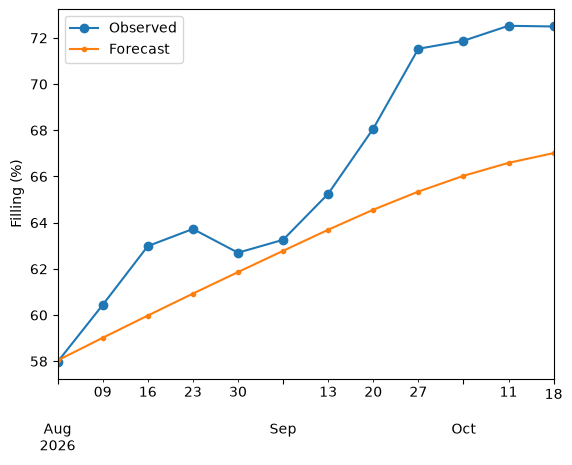

In [3]:
# Evaluate four consecutive, non-overlapping forecast periods using earlier data only.
rows = []
for lag in [2, 4, 8]:
    start = time.perf_counter()
    errors, baseline = [], []
    for offset in [48, 36, 24, 12]:
        history = filling.iloc[:-offset]
        forecast = forecast_filling(history, history=104, horizon=12, lags=lag)
        actual = filling.reindex(forecast.index)
        errors.extend((forecast - actual).abs())
        baseline.extend((history.iloc[-1] - actual).abs())
    rows.append([lag, 100 * pd.Series(errors).mean(), 100 * pd.Series(baseline).mean(), time.perf_counter()-start])
print(pd.DataFrame(rows, columns=["Lags", "MAE (pp)", "Persistence MAE (pp)", "Seconds"]).round(3))
ax = actual.mul(100).plot(label="Observed", marker="o")
forecast.mul(100).plot(ax=ax, label="Forecast", marker=".")
ax.set_ylabel("Filling (%)")
ax.legend()
plt.show()

## Weather and filling

0 -0.77 0.83
1 -0.73 0.92
4 -0.92 0.88


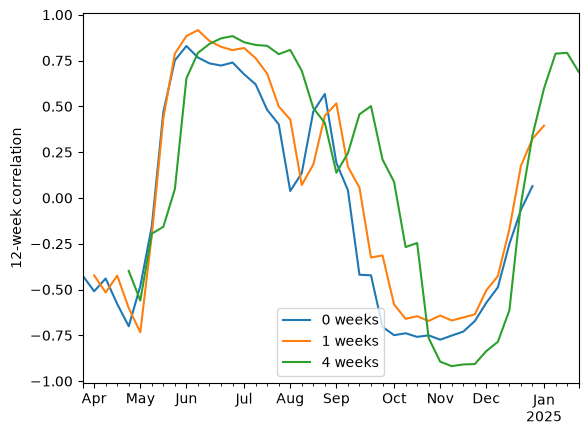

In [4]:
# Compare correlations on complete overlapping weeks for three weather leads.
fig, ax = plt.subplots()
for lag in [0, 1, 4]:
    corr = sliding_correlation(filling, weekly.temperature_2m, lag, 12)
    print(lag, round(corr.min(), 2), round(corr.max(), 2))
    corr.plot(ax=ax, label=f"{lag} weeks")
ax.set_ylabel("12-week correlation")
ax.legend()
plt.show()

## Work log

The map gives the app a starting point. Someone interested in one reservoir area can choose it once and carry that choice into the analyses. The data table and the comparison plots sit together because they answer similar questions. The weather and reservoir pages have local controls for choices that only make sense there, such as the length of a correlation window. The navigation sketch was made before changing the app code.

I used the weekly observations from EL 3 to compare forecasts. Working at a finer resolution would mean estimating filling levels between observations. It would also make a one-week lag harder to explain. The model therefore takes one step for each new NVE observation. I compared two, four and eight previous weeks using the same four forecast periods. Eight gave the lowest average error of those settings, about 6.48 percentage points. This is the starting setting in the app. The results cover one area and four periods, so they give a limited picture of how the model performs elsewhere.

The relationship with temperature varied within the year. In the twelve-week windows, the correlation at zero lag ranged from about −0.77 to 0.83. Moving temperature back one week raised the highest value to about 0.92, but some windows still had a negative correlation. That makes a single correlation for the whole year difficult to interpret. A strong value in a short window is also a weak basis for choosing a predictor without checking its performance on later observations.

I chose error handling as the bonus task. When NVE cannot be reached, the app explains that it is showing the saved observations. The weather page checks that a complete regional dataset exists. The correlation calculation checks the number of observations in each local week before using it. This matters particularly at the beginning and end of the weather record, where a partial week could look like a week with very little precipitation. The forecast page also explains when the chosen period leaves too few observations for training.

## AI use

OpenAI Codex helped substantially with the navigation sketch, implementation, model comparison, testing and English wording. The calculations above use the project data. The reported errors and correlations come from running the code.